# Computer Vision - P4


==============================================================================================
# **Practice 4: Image descriptors and Texture analysis**
==============================================================================================

### The main topics covered in P4 are:

- HOG image descriptor for object (person) detection.
- Keypoint detection and feature matching using CENSURE, ORB, and SIFT.
- Image Search Using Texture Descriptors

### Improving Code Reusability
It is highly recommended to organize the code into functions to promote code reuse across different tests and images, while making it shorter and easier to read. In particular, visualization commands should be encapsulated in separate functions.

# **HOG Image Descriptor: Application to Person Detection**

In this section, we will explore the **Histogram of Oriented Gradients (HOG)** image descriptor and its application to person detection.

HOG is a classical feature descriptor widely used in computer vision for object detection. It captures the distribution of gradient orientations within an image, providing useful information about object shape and appearance.

Given the image `person_template.bmp` and the collection of images in the folder `/images_p4/TestPersonImages/`, apply the HOG descriptor to detect the presence and location of any person in the images. To achieve this, use the **sliding window technique**, which consists of moving a detection window across different regions of each image and evaluating whether each region contains a person.

For this exercise, we will use images from the **GRAZ 01 dataset**, available through the [INRIA Person Dataset collection](http://pascal.inrialpes.fr/data/human/).

### Exercise 1: Computing and Visualizing the HOG Descriptor

Load the template image (`person_template.bmp`), preprocess it, and compute its Histogram of Oriented Gradients (HOG) descriptor.

**Help:** The HOG descriptor function is available in the `skimage.feature` library. Refer to the [HOG documentation and example](https://scikit-image.org/docs/stable/auto_examples/features_detection/plot_hog.html) for guidance.

The helper functions `ensure_gray()` and `normalize()` are defined in the cells below and should be used for image preprocessing.

Compute two versions of the HOG descriptor:

1. **Default parameters:** Use the default parameter values provided by the HOG function.
2. **Custom parameters:** Set the following values:
   - Pixels per cell: 4 × 4.
   - Cells per block: 2 × 2.
   - Number of orientations: 8.

**Visualization:** Display the following three images side by side in a 1 × 3 grid:

1. The preprocessed original template image.
2. The HOG visualization computed using the default parameters.
3. The HOG visualization computed using the custom parameters.

Expected result is illustrated below:

<img src="images_p4/hog_result.jpg" width=800>

### Normalización

En la siguiente celda definimos la función `normalize()`, que permite normalizar los valores de intensidad de la imagen al intervalo [0, 1] mediante el método min-max. También se contempla el caso en que todos los píxeles tienen el mismo valor, evitando así una división por cero.

In [2]:
import numpy as np

def normalize(img):
    img = img.astype(float)
    min_val = img.min()
    max_val = img.max()

    if max_val == min_val:
        return np.zeros_like(img)

    return (img - min_val) / (max_val - min_val)

### Conversión de imágenes a escala de grises

En la siguiente celda definimos la función `ensure_gray()`, que garantiza que la imagen de entrada esté en escala de grises. Para ello, detecta si la imagen es RGB o RGBA, elimina el canal alfa cuando es necesario y convierte los canales RGB a escala de grises. Si la imagen ya está en escala de grises, se mantiene sin modificaciones.

In [3]:
# Define ensure_gray()
def ensure_gray(img):
    # Already grayscale
    if img.ndim == 2:
        return img

    # Remove alpha channel (RGBA -> RGB)
    if img.ndim == 3 and img.shape[2] == 4:
        img = img[:, :, :3]

    # Convert RGB to grayscale
    if img.ndim == 3 and img.shape[2] == 3:
        img = rgb2gray(img)

    return img

Template shape: (129, 49), dtype: float64, min: 0.0, max: 1.0


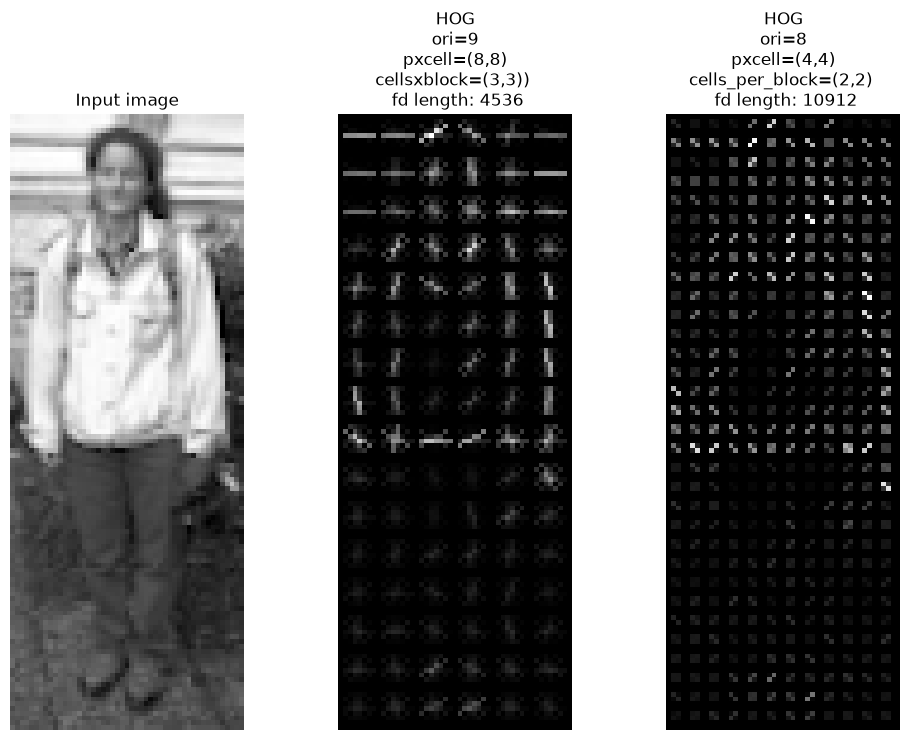

In [4]:
from skimage.feature import hog
from skimage import exposure, io
from skimage.color import rgb2gray
import matplotlib.pyplot as plt

# Read and prepare template (ensure_gray)
tpl = ensure_gray(io.imread("images_p4/person_template.bmp"))

# Normalize
tpl = normalize(tpl)

print(f"Template shape: {tpl.shape}, dtype: {tpl.dtype}, min: {tpl.min()}, max: {tpl.max()}")


# default HOG (skimage default: orientations=9, pixels_per_cell=(8,8), cells_per_block=(3,3))
fd1, hog_image1 = hog(
    tpl,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(3, 3),
    visualize=True,
)

# custom HOG: 4x4 pixels per cell, 2x2 cells per block, 8 orientations
fd2, hog_image2 = hog(
    tpl,
    orientations=8,
    pixels_per_cell=(4, 4),
    cells_per_block=(2, 2),
    visualize=True,
)


# rescale HOG visualizations for display
hog_image_rescaled_1 = exposure.rescale_intensity(hog_image1, in_range=(0, 10))
hog_image_rescaled_2 = exposure.rescale_intensity(hog_image2, in_range=(0, 10))

fig, ax = plt.subplots(1, 3, figsize=(12, 8))

ax[0].axis('off')
ax[0].imshow(tpl, cmap='gray')
ax[0].set_title('Input image')

ax[1].axis('off')
ax[1].imshow(hog_image_rescaled_1, cmap=plt.cm.gray)
ax[1].set_title('HOG\nori=9\npxcell=(8,8)\ncellsxblock=(3,3)) \n fd length: {}'.format(len(fd1)))

ax[2].axis('off')
ax[2].imshow(hog_image_rescaled_2, cmap=plt.cm.gray)
ax[2].set_title('HOG\nori=8\npxcell=(4,4)\ncells_per_block=(2,2) \n fd length: {}'.format(len(fd2)))
plt.show()

### Exercise 2: Person Detection Using HOG Descriptors

Apply the Histogram of Oriented Gradients (HOG) descriptor to detect the person template in a set of test images using a sliding-window approach.

**Tasks:**

**a) Sliding-window detection**

Read all images from the folder `images_p4/TestPersonImages`. For each test image:

1. Slide a window across the image using a predefined window size and stride.
2. Extract the HOG descriptor for each window, using the same HOG parameters as those used to compute the person template descriptor.
3. Compare each window's HOG descriptor with the HOG descriptor of the person template.
4. Compute the distance between the descriptors to measure their similarity.

**b) Person localization**

For each test image:

1. Identify the window with the smallest descriptor distance to the person template.
2. Determine the location of the most similar window in the original image.
3. Draw a bounding box around the detected region to indicate the most likely location of the person.

**Visualization:**

Display the person detection results for every test image, showing the original image and the detected bounding box.

Use the following example as a reference for the expected output:

<img src="images_p4/hog.jpg" width="800">

**Note:** A smaller distance between HOG descriptors indicates greater similarity between the image window and the person template. The detection process should be repeated for every image in the test folder.

In [ ]:
import os, glob
from matplotlib import patches

# Function to detect the person template in an image using a sliding-window approach
def detect_person_hog(image, template, hog_params, step=8):
    h, w = template.shape
    x_detect, y_detect, similarity_detect = 0, 0, np.inf

    if image.shape[1] < w or image.shape[0] < h:
        print("Image is smaller than template. Skipping detection.")
        return

    fd_template, hog_template = hog(template, **hog_params)
    fd_img, hog_img = hog(image, **hog_params)

    hog_image_rescaled = exposure.rescale_intensity(hog_img, in_range=(0, 10))

    for y in range(0, image.shape[0] - h + 1, step):
        for x in range(0, image.shape[1] - w + 1, step):
            window = image[y:y + h, x:x + w]
            fd_window, hog_window = hog(window, **hog_params)

            similarity = np.linalg.norm(fd_template - fd_window)

            if similarity_detect > similarity:  # Threshold for detection
                x_detect, y_detect = x, y
                similarity_detect = similarity

    return hog_image_rescaled, x_detect, y_detect, similarity_detect



path = glob.glob(os.path.join("images_p4/TestPersonImages", "*.bmp"))
images = [normalize(ensure_gray(io.imread(p))) for p in path]
tmpl = normalize(ensure_gray(io.imread("images_p4/person_template.bmp")))

hog_params = {
    'orientations': 9,
    'pixels_per_cell': (8, 8),
    'cells_per_block': (3, 3),
    'visualize': True
}

hog_params2 = {
    'orientations': 8,
    'pixels_per_cell': (4, 4),
    'cells_per_block': (2, 2),
    'visualize': True
}

for image in images:
    hog_img, x, y, sim = detect_person_hog(image, tmpl, hog_params, step=8)

    fig, ax = plt.subplots(1, 3, figsize=(12, 8))
    ax[0].imshow(tmpl, cmap='gray')
    ax[0].axis('off')
    ax[0].set_title('Template')

    ax[1].imshow(image, cmap='gray')
    ax[1].axis('off')
    ax[1].set_title('Input image')
    ax[1].add_patch(patches.Rectangle((x, y), tmpl.shape[1], tmpl.shape[0], linewidth=1.5, edgecolor='r', facecolor='none'))

    ax[2].imshow(hog_img, cmap='gray')
    ax[2].axis('off')
    ax[2].set_title('HOG features')
    ax[2].add_patch(patches.Rectangle((x, y), tmpl.shape[1], tmpl.shape[0], linewidth=1.5, edgecolor='r', facecolor='none'))

    plt.show()

Image is smaller than template. Skipping detection.


TypeError: cannot unpack non-iterable NoneType object

### Evaluation and Discussion

Count the number of test images in which the person was correctly detected and discuss the cases in which the algorithm failed.

**Questions:**

1. In how many test images was the person correctly detected?
2. Which images produced incorrect detections, and what might explain these failures?

**Answer:**

Several factors can explain failures in person detection using HOG descriptors:

- **Lighting variations:** Changes in illumination, shadows, or contrast can affect the gradient information extracted by HOG.
- **Occlusions:** Parts of the person may be hidden by other objects, resulting in incomplete or misleading descriptors.
- **Pose and orientation variations:** Different body poses or viewing angles can produce HOG descriptors that differ significantly from the template.
- **Scale variations:** The person may appear larger or smaller than in the template. Since the sliding window uses a fixed size, it may fail to match the person correctly.
- **Background interference:** Background regions with similar gradient patterns may produce descriptors close to the person template, leading to false detections.
- **Limited template representation:** A single template may not capture the variability in human appearance, clothing, and posture.


### Optional Exercise: Fine-Tuning HOG Parameters

Experiment with different HOG parameter configurations to investigate whether person detection performance can be improved.

**Tasks:**

1. Modify the HOG parameters used for feature extraction and detection. In particular, experiment with different values for:
   - `orientations`: Number of orientation bins.
   - `pixels_per_cell`: Size of each cell in pixels.
   - `cells_per_block`: Number of cells in each block.
   - `block_norm`: Block normalization method.

2. Run the person detection algorithm using different parameter configurations. Remember that **the same HOG parameters must be used for both the template and the sliding windows**.

3. Evaluate the detection results for each configuration. Count the number of correctly detected persons and compare the detection success rates.

4. Identify the parameter configuration that produces the best results on the test images.

**Discussion:**

Include a short discussion (approximately one paragraph) addressing the following questions:

- Which HOG parameter configuration produced the best detection results?
- Did changing the parameters improve the detection success rate? By how much?
- How did the changes affect the similarity distance values and the detected bounding boxes?
- Can you explain why certain parameter configurations performed better or worse?

**Note:** This is an optional exercise. There is no single correct parameter configuration. The goal is to understand how HOG parameters influence feature extraction and person detection performance.

In [ ]:
# Your solution here



# **ORB Feature Detector and Binary Descriptor**

Feature extraction in computer vision involves two closely related tasks:

- **Feature detection (keypoint localization):** Identifying distinctive points in an image, such as corners and textured regions.
- **Feature description:** Computing a descriptor that represents the local image appearance around each detected keypoint, allowing it to be matched across different images.

In this exercise, we will explore **ORB (Oriented FAST and Rotated BRIEF)**, a feature detection and description algorithm designed to be computationally efficient and suitable for real-time applications. The main objective is to investigate the robustness of ORB features to **image rotation and scale changes**. In particular, we will analyse to what extent ORB can detect and match corresponding features when the same scene or object is viewed at different orientations and scales.

**Hint:** The `ORB` class is available in the `skimage.feature` module.

**Help:** Refer to the [ORB example in the scikit-image documentation](https://scikit-image.org/docs/stable/auto_examples/features_detection/plot_orb.html) for guidance on detecting keypoints, computing binary descriptors, and matching features. You can use `match_descriptors()` from `skimage.feature` to find correspondences between descriptors extracted from different images.


### Exercise: Keypoint Detection Using the CENSURE Detector

First, apply the **CENSURE (CENsus TRansform hUncanny REgions)** detector to the image `starbucks4.jpg` to identify distinctive keypoints.

**Tasks:**

1. Load the image `starbucks4.jpg` and convert it to grayscale if necessary.
2. Apply the CENSURE detector using the `CENSURE` class available in `skimage.feature`.
3. Visualize the detected keypoints on the original image.
4. Experiment with different values of the CENSURE parameters and observe how they affect keypoint detection. In particular, investigate the effect of:
   - `min_scale` and `max_scale`: Minimum and maximum scales at which keypoints are detected.
   - `mode`: Scale-space construction method.
   - `non_max_threshold`: Threshold used for non-maximum suppression.
   - `line_threshold`: Threshold controlling the rejection of edge-like responses.

**Discussion:** Compare the detection results obtained with different parameter configurations. 

**Note:** CENSURE is a keypoint detector, not a descriptor. Its purpose is to locate distinctive image regions. In the following exercises, you will use ORB to compute descriptors and match features between images.

Use the following example as a reference for the expected output:

<img src="images_p4/starbucks4_result.jpg" width="800">

In [ ]:
# Your solution here





### Exercise: ORB Feature Matching Between Model and Scene Images

Use ORB to detect and match features between the model image (`starbucks.jpg`) and the scene image (`starbucks4.jpg`).

**Tasks:**

1. Detect keypoints and compute binary descriptors in both images using ORB.
2. Match the descriptors using `match_descriptors()` from `skimage.feature`.
3. Visualize the detected keypoints and the resulting correspondences.
4. Implement a reusable function called `get_ORB()` to perform feature extraction and matching. Add detailed comments explaining the main steps.

**Parameter Analysis and Discussion:**

Experiment with different values of the `max_ratio` parameter in `match_descriptors()` and discuss their effect on:
- The number of feature matches.
- The reliability of the correspondences.
- The occurrence of false matches.

**Hint:** You can adapt the code from the [ORB example in the scikit-image documentation](https://scikit-image.org/docs/stable/auto_examples/features_detection/plot_orb.html).

Use the following example as a reference for the expected output:

<img src="images_p4/starbucks4_result2.jpg" width="800">

In [ ]:
# Your solution here



### Exercise: Ranking Starbucks Images by Similarity

Use `starbucks.jpg` as the model image and match its ORB features against all available Starbucks scene images (i.e., `starbucks2.png`, `starbucks4.jpg`, `starbucks5.png`, `starbucks6.jpg`,`starbucksCup.jpg`).

**Tasks:**

1. Extract and match ORB descriptors for each scene image.
2. Rank the images from most to least similar based on the number of reliable matches.
3. Visualize the feature correspondences for each image.

**Discussion:** Which images produce the best matches? Under what conditions does ORB perform better or worse?

In [ ]:
# Your solution here

# res = match_orb_images("images_p4/starbucks.jpg", "images_p4/starbucks2.png",
#                        n_keypoints=800, fast_threshold=0.08,
#                        max_ratio=0.8, cross_check=False, plot_top=150)

In [ ]:
# Your solution here

# res = match_orb_images("images_p4/starbucks.jpg", "images_p4/starbucks4.jpg",
#                        n_keypoints=800, fast_threshold=0.08,
#                        max_ratio=0.8, cross_check=False, plot_top=150)

In [ ]:
# Your solution here

# res = match_orb_images("images_p4/starbucks.jpg", "images_p4/starbucks5.png",
#                        n_keypoints=800, fast_threshold=0.08,
#                        max_ratio=0.8, cross_check=False, plot_top=150)

In [ ]:
# Your solution here

# res = match_orb_images("images_p4/starbucks.jpg", "images_p4/starbucks6.jpg",
#                        n_keypoints=800, fast_threshold=0.08,
#                        max_ratio=0.8, cross_check=False, plot_top=150)

In [ ]:
# Your solution here

res = match_orb_images("images_p4/starbucks.jpg", "images_p4/starbucksCup.jpg",
                       n_keypoints=800, fast_threshold=0.08,
                       max_ratio=0.8, cross_check=False, plot_top=150)

# **Feature Matching Using SIFT**

Repeat the previous experiment using **SIFT** instead of ORB. Use `starbucks.jpg` as the model image and match its features against all the available Starbucks scene images. Start with the default SIFT parameters.

**Tasks:**

1. Extract and match SIFT features for all scene images.
2. Rank the images from most to least similar and visualize the feature correspondences.
3. Measure and compare the execution time of SIFT and ORB.

**Discussion:**

Compare the matching results and computational efficiency of both algorithms. Which performs better for this particular set of images, and why?

Use the following example as a reference for the expected output:

<img src="images_p4/starbucks4_result3.jpg" width="800">

In [ ]:
# Your solution
from skimage.feature import SIFT




### Exercise: Exploring SIFT Parameters and Comparing ORB and SIFT

Investigate how different SIFT parameter configurations affect feature detection and matching between the model image (`starbucks.jpg`) and the scene image (`starbucks4.jpg`).

**Tasks:**

1. Experiment with at least three different combinations of SIFT parameters.
2. Visualize and compare the detected keypoints and feature matches for each configuration.
3. Analyse the effect of changing the parameters on the number and quality of the matches.

**Discussion:**

Compare SIFT and ORB in terms of their robustness to:
- Image rotation.
- Scale changes (resizing).
- Intensity and illumination variations.

In [ ]:
# Your solution here




---

# **Image Search Using Texture Descriptors**


Given a query image **$x$** and a collection of images **$X$**, the goal is to retrieve the images in **$X$** that are most similar to **$x$**.

In this notebook, we will explore image similarity search using:

- Gaussian filtering for image preprocessing.
- Texture-based image descriptors.
- Distance measures to compare images and rank search results.

## Derivatives of Gaussians (DoG): The Leung–Malik (LM) Filter Bank

A **filter bank** is a collection of filters applied to an image to extract different types of visual features. If we apply \(D\) filters, each pixel is represented by a \(D\)-dimensional feature vector, with each component corresponding to the response of one filter.

A filter bank is typically designed to capture patterns at different **scales** and **orientations**, allowing it to respond to a variety of image structures and textures.

The filter bank shown below is the **Leung–Malik (LM) filter bank**, which includes filters based on Gaussian derivatives and other filters designed to capture different texture properties.

<img src="./images_p4/filter_bank.png" width="1000">

We import the **Leung–Malik (LM) filter bank** implementation from the following GitHub repository: [LM Filter Bank – Python implementation](https://github.com/tonyjo/LM_filter_bank_python/tree/master)

In [ ]:
from util.lm import *

### Ejercicio. Visualización del banco de filtros LM

Utiliza la implementación del banco de filtros Leung–Malik (LM) para generar el conjunto de filtros y visualizar todos sus elementos.

Representa los filtros en una única figura, organizados en una cuadrícula. Utiliza una escala de grises para facilitar la interpretación de sus patrones y orientaciones.

**Nota:** Añade un título a cada filtro e identifica el número total de filtros que componen el banco.

Use the following example as a reference for the expected output:

<img src="images_p4/filter_result.jpg" width="800">

In [ ]:
# your solution here 



### Image Loading and Preprocessing

Load the image `/images_p4/dog.jpg` and resize it to **240 × 240 pixels**. Convert the resized image to grayscale.

Display both the resized RGB image and its grayscale version side by side.




In [ ]:
# your solution here 



### Texture Feature Extraction

Given a filter bank containing \(D\) filters and an input grayscale image `image`, implement a function `get_image_features(image, filter_bank, n_filters)`.

The function must return a feature vector of length `n_filters`, where each element contains the mean of the absolute values of the image response obtained by convolving the image with the corresponding filter.

The resulting feature vector is defined as:

$$
\operatorname{feat}(x) =
\begin{bmatrix}
\operatorname{mean}(|r_1|) &
\operatorname{mean}(|r_2|) &
\cdots &
\operatorname{mean}(|r_D|)
\end{bmatrix}
$$

where each filter response is given by:

$$
r_k = x * f_k, \qquad k = 1, 2, \ldots, D
$$

Here:
- \(x\) is the input grayscale image.
- \(f_k\) is the \(k\)-th filter.
- \(r_k\) is the corresponding filter response.
- \(D\) is the number of filters.
- \(*\) denotes convolution.

Test your function using the image loaded in previous cell and print the resulting feature vector.

**Hint:** Start by using a small subset of filters to test your implementation before applying the entire filter bank.

In [ ]:
# your solution here 



### Visualizing Filter Responses

Implement a function `visualize_features(im, filter_bank, n_filters=5)` that takes an input image `im`, a filter bank `filter_bank`, and the number of filters to visualize `n_filters`.

The function must generate a figure with **two rows and `n_filters` columns**:

- **First row:** Display the response obtained by convolving the input image with each filter.
- **Second row:** Display the corresponding filter.

For example, when `n_filters=5`, the output should look like:

<img src="images_p4/dog_result.jpg" width="1000">

**Hint:** Since we are focusing on texture analysis, convert the input image to grayscale before applying the filters. Do not use color information.

In [ ]:
# your solution here 



### Loading, Resizing, and Storing a Small Image Dataset

Load all `.jpg` images from the `/images_p4/pets/` directory. Convert each image to grayscale, resize it to **240 × 240 pixels**, and store the resulting images in a NumPy array for further processing.

In [ ]:
# your solution here 



### Constructing the Feature Matrix for the Image Dataset

Implement a function `get_dataset_features(images, filter_bank, n_filters=8)` that applies the previously implemented `get_image_features()` function to each image in the dataset.

Use **8 filters** (`n_filters=8`) to extract the texture features.

The function must return a **feature matrix** with one column per image and one row per feature. Therefore, for a dataset containing $N$ images and using $D=8$ filters, the resulting matrix must have shape $(D,N) = (8,N)$.

Each column represents the feature vector extracted from one image, while each row corresponds to a particular filter.

In [ ]:
# your solution here 

# def get_dataset_features(images, filter_bank, n_filters=8):
#
#
#     return feature_matrix




# Retrieving the Most Similar Images

### Similarity Search

Let $f(x) \in \mathbb{R}^D$ denote the $D$-dimensional feature vector extracted from an image $x$. Given a query image $x$ and a database containing images $x^1, x^2, \ldots, x^N$, we can measure the similarity between the query image and each database image using the **Euclidean (L2) distance** between their feature vectors:

$$
d(x, x^m) = \|f(x) - f(x^m)\|_2
= \sqrt{\sum_{d=1}^{D} \left(f_d(x) - f_d(x^m)\right)^2}
$$

where $f_d(x)$ denotes the $d$-th feature of image $x$.

A smaller distance indicates greater similarity between the images. Therefore, the most similar image in the database is the one whose feature vector has the smallest Euclidean distance to that of the query image:

$$
m^* = \underset{m \in \{1,\ldots,N\}}{\operatorname{argmin}}
\; d(x, x^m)
$$

By sorting the database images according to their distances from the query image, we can retrieve the **top-$K$ most similar images**.

### Exercise: Retrieving the Top 5 Most Similar Images

Use the previously loaded `dog.jpg` image as the **query image** and retrieve the five most similar images from the dataset.

1. Extract the texture feature vector of the query image using `get_image_features()`. **Important:** Use `n_filters=8`, matching the number of filters used to extract the features of the dataset images.
2. Compute the Euclidean distance between the query feature vector and the feature vectors of all images in the dataset.
3. Identify the indices of the five images with the smallest distances.
4. Display the query image alongside the **top 5 most similar images** retrieved from the dataset. Include the corresponding distance values in the plot titles.

**Hint:** Use `np.linalg.norm()` to compute the Euclidean distance and `np.argsort()` to find the indices of the closest images.

Use the following example as a reference for the expected output:

<img src="images_p4/retrieval_result.jpg" width="1000">

In [ ]:
# your solution here 



### Optional Exercise: Exploring the Effect of the Number of Filters

Repeat the similarity search experiment using a larger number of filters (e.g., 16, 24, or all available filters in the LM filter bank).

1. Recompute the feature matrix for the entire dataset using the selected number of filters.
2. Extract the feature vector of the query image (`dog.jpg`) using the **same number of filters**.
3. Repeat the similarity search and display the top 5 most similar images.
4. Compare the retrieval results obtained with different numbers of filters.

**Discussion:** Does increasing the number of filters improve the retrieval results? Discuss the advantages and disadvantages of using more filters, considering aspects such as retrieval accuracy, feature representation, computational cost, and processing time.

In [ ]:
# you solution here

